<a href="https://colab.research.google.com/github/jeevithajeevitha3420-create/Data-Science/blob/main/Task_3_DS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("customer_transactions_dataset.csv", parse_dates=["InvoiceDate"])
print(df.shape)
df.info()
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print("Returns:", (df["Quantity"] <= 0).sum(), "Zero price:", (df["UnitPrice"] <= 0).sum())

(36455, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36455 entries, 0 to 36454
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   CustomerID   36395 non-null  float64       
 1   InvoiceNo    36455 non-null  int64         
 2   InvoiceDate  36455 non-null  datetime64[ns]
 3   Quantity     36455 non-null  int64         
 4   UnitPrice    36455 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2)
memory usage: 1.4 MB
CustomerID     60
InvoiceNo       0
InvoiceDate     0
Quantity        0
UnitPrice       0
dtype: int64
Duplicates: 321
Returns: 40 Zero price: 15


In [ ]:
df = df.dropna(subset=["CustomerID"]).drop_duplicates()
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
df["CustomerID"] = df["CustomerID"].astype(int)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print(len(df), df["CustomerID"].nunique(), round(df["Revenue"].sum()))
# expect 36019 rows, 1500 customers, revenue about 1,744,881

36019 1500 1744881


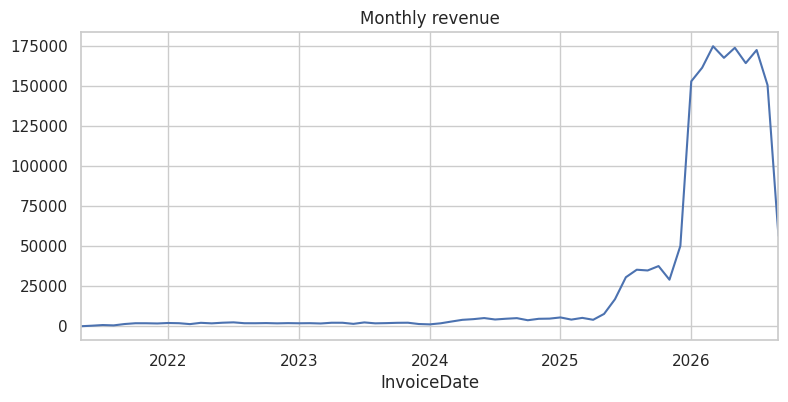

In [ ]:
monthly = df.set_index("InvoiceDate")["Revenue"].resample("ME").sum()
monthly.plot(title="Monthly revenue", figsize=(9, 4)); plt.show()

In [ ]:
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")).round(2)

print(rfm.describe().round(2))

       Recency  Frequency  Monetary
count  1500.00    1500.00   1500.00
mean    177.78       9.69   1163.25
std     187.01       5.29   1009.57
min       1.00       1.00      4.91
25%      42.00       6.00    382.21
50%     103.00      10.00    783.02
75%     265.50      13.00   1825.90
max    1093.00      26.00   5118.16


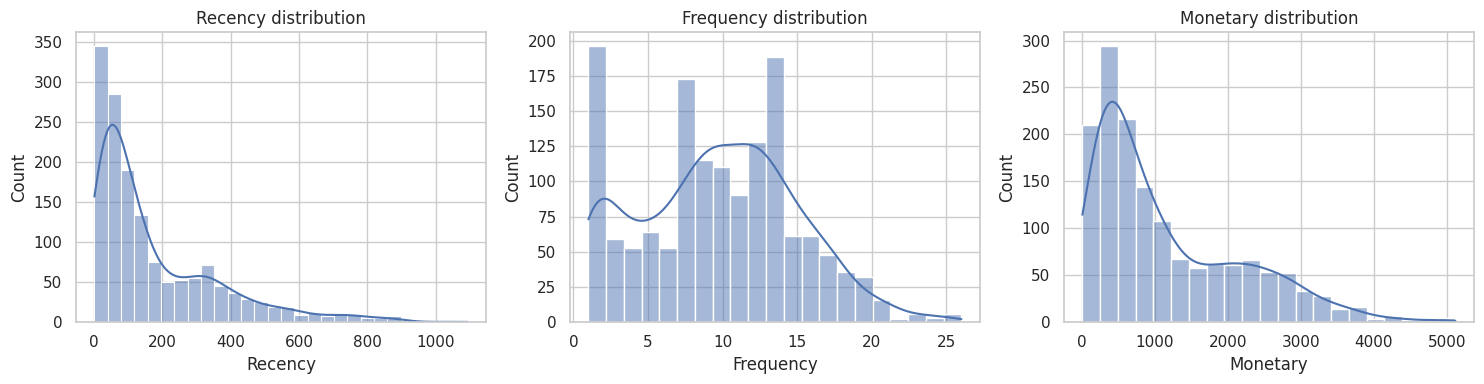

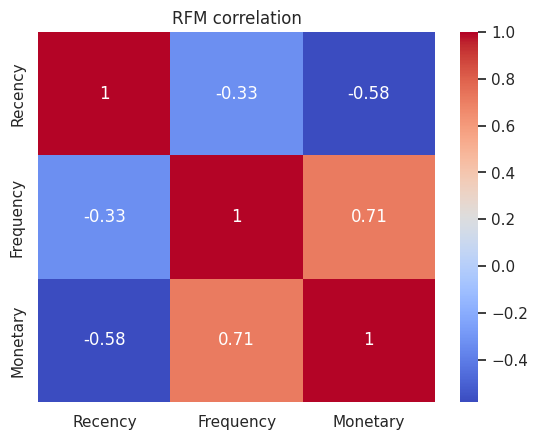

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, c in enumerate(rfm.columns):
    sns.histplot(rfm[c], kde=True, ax=ax[i]).set(title=f"{c} distribution")
plt.tight_layout(); plt.show()

sns.heatmap(rfm.corr(), annot=True, cmap="coolwarm"); plt.title("RFM correlation"); plt.show()

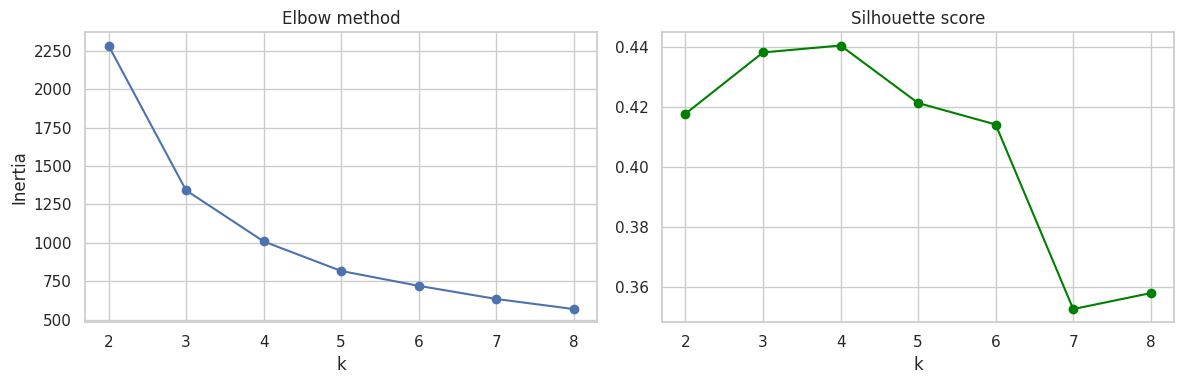

{2: np.float64(0.418), 3: np.float64(0.438), 4: np.float64(0.441), 5: np.float64(0.421), 6: np.float64(0.414), 7: np.float64(0.353), 8: np.float64(0.358)}


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = StandardScaler().fit_transform(np.log1p(rfm))   # log reduces skew, then scale

ks = range(2, 9); inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set(title="Elbow method", xlabel="k", ylabel="Inertia")
ax[1].plot(ks, sil, "o-", color="green"); ax[1].set(title="Silhouette score", xlabel="k")
plt.tight_layout(); plt.show()
print(dict(zip(ks, np.round(sil, 3))))

In [ ]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
rfm["Cluster"] = km.labels_

profile = rfm.groupby("Cluster").agg(
    Customers=("Recency", "size"), Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"), Monetary=("Monetary", "mean")).round(1)
profile["Revenue_share_%"] = (rfm.groupby("Cluster")["Monetary"].sum() / rfm["Monetary"].sum() * 100).round(1)
print(profile.sort_values("Monetary", ascending=False))

         Customers  Recency  Frequency  Monetary  Revenue_share_%
Cluster                                                          
0              484     34.8       14.0    2406.1             66.7
2              492    117.4        7.9     847.9             23.9
1              258    382.6       13.0     424.5              6.3
3              266    350.9        2.0     201.6              3.1


In [ ]:
names = {}
names[profile["Monetary"].idxmax()] = "Champions"
rest = [c for c in profile.index if c not in names]
lapsed = sorted(rest, key=lambda c: profile.loc[c, "Recency"], reverse=True)[:2]
names[max(lapsed, key=lambda c: profile.loc[c, "Frequency"])] = "Lapsed Regulars (At-risk)"
names[min(lapsed, key=lambda c: profile.loc[c, "Frequency"])] = "Lost / One-time Buyers"
names[[c for c in rest if c not in lapsed][0]] = "Loyal / Potential Loyalists"

rfm["Segment"] = rfm["Cluster"].map(names)
profile["Segment"] = profile.index.map(names)
print(profile.sort_values("Monetary", ascending=False).to_string())

         Customers  Recency  Frequency  Monetary  Revenue_share_%                      Segment
Cluster                                                                                       
0              484     34.8       14.0    2406.1             66.7                    Champions
2              492    117.4        7.9     847.9             23.9  Loyal / Potential Loyalists
1              258    382.6       13.0     424.5              6.3    Lapsed Regulars (At-risk)
3              266    350.9        2.0     201.6              3.1       Lost / One-time Buyers


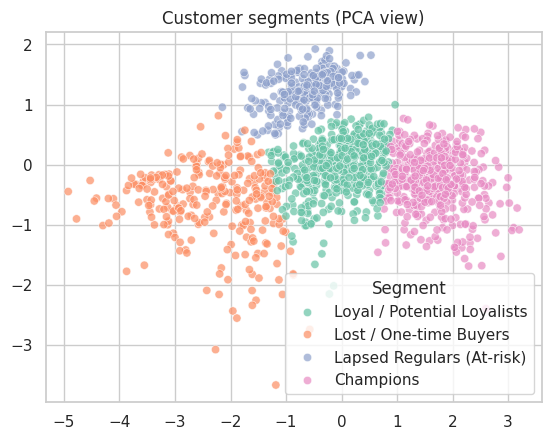

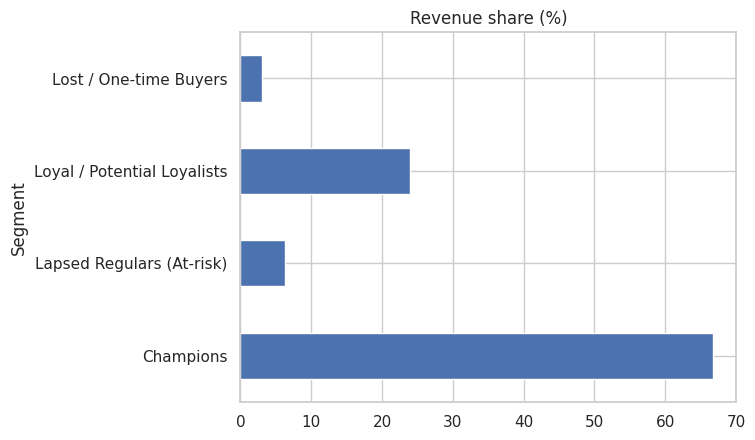

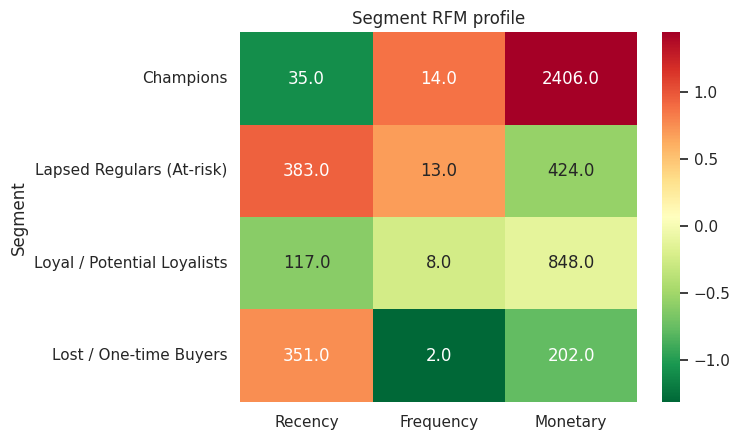

In [ ]:
from sklearn.decomposition import PCA
pc = PCA(n_components=2).fit_transform(X)
sns.scatterplot(x=pc[:, 0], y=pc[:, 1], hue=rfm["Segment"], palette="Set2", alpha=0.7)
plt.title("Customer segments (PCA view)"); plt.show()

profile.set_index("Segment")["Revenue_share_%"].plot.barh(title="Revenue share (%)"); plt.show()

g = profile.set_index("Segment")[["Recency", "Frequency", "Monetary"]]
sns.heatmap((g - g.mean()) / g.std(), annot=g.round(0), fmt="", cmap="RdYlGn_r")
plt.title("Segment RFM profile"); plt.show()